# Fenología satelital y ensamble del dataset maestro (02_fenologia)

Este notebook transforma las series de índices de vegetación ya limpias en el 01_base_limpia (`pl_limpio.parquet` y `s2_limpio.parquet`) en **métricas fenológicas por parcela** y, al final, ensambla el **dataset maestro** de 197 parcelas que usa el EDA.

La fenología de superficie terrestre estima, a partir de series temporales de un índice como el NDVI, cuándo inicia el reverdecimiento, cuándo se alcanza el máximo vigor y cuándo termina la senescencia (Reed et al., 1994; Zeng et al., 2020). Para la cebada de temporal estas fechas son relevantes porque ubican en el tiempo las etapas en las que el agua y la temperatura limitan el rendimiento, y porque el verdor acumulado durante el ciclo se ha usado como predictor del rendimiento de cereales, entre ellos la cebada (Mkhabela et al., 2011).

**El flujo sigue cuatro etapas:**

1. **Suavizado** de la serie diaria de NDVI con el suavizador de Whittaker (Eilers, 2003).
2. **Detección del ciclo productivo** y cálculo de fechas por umbrales de amplitud (Jönsson y Eklundh, 2004).
3. **Contraste entre sensores**: Planet como serie principal y Sentinel-2 como verificación independiente.
4. **Ensamble del maestro** con contratos de datos, poda de redundancia y controles de fuga y de desplazamiento.

## Carga de insumos y contratos de entrada

- Se cargan solo las columnas que usa el cálculo: el NDVI y el LAI de Planet, el NDVI de Sentinel-2 y las banderas `es_descartado`, `es_interpolado` y `hueco_dias`.
- Se recorta Sentinel-2 a la misma ventana del ciclo que Planet, del **1 de marzo al 30 de noviembre de 2025**.
- **Planet es la serie principal** y **Sentinel-2 es un apoyo** para ubicar fechas: sus valores nunca se promedian ni se combinan.
- Antes de cualquier cálculo se verifican contratos con `assert`: 197 parcelas únicas, objetivo vacío en el conjunto de predicción, fechas de tipo `datetime`, sin duplicados por parcela y fecha, y Planet dentro de la ventana.

**Justificación**
- En archivo pasado, `es_descartado` marca las escenas nubladas o sin valores, y la interpolación solo se aplica sobre esas filas. Por lo tanto, `~es_descartado` identifica exactamente las **observaciones reales**, y es la máscara que se usará en el suavizado. [Evidencia, notebook `01_base_limpia`]

- Cada sensor tiene su propia respuesta radiométrica y su propia resolución. La literatura compara las métricas fenológicas de PlanetScope y de Landsat/Sentinel-2 como productos separados, y encuentra buena concordancia con sesgo despreciable **(Moon et al., 2021).** Esto respalda usar Sentinel-2 como verificación independiente en lugar de mezclar ambos valores en una sola serie.

- Las verificaciones automáticas de calidad tratan los datos como código que debe pasar pruebas antes de entrar a un proceso posterior **(Schelter et al., 2018)**. El `assert` sobre el objetivo en `PREDICCION` evita una fuga de información desde el inicio (Kaufman et al., 2012).

- La ventana de marzo a noviembre cubre el ciclo de temporal del Altiplano, donde alrededor del 75 % de la superficie de cebada maltera se siembra bajo temporal  **(González González et al., 2016).** 


In [ ]:
#Biblotecas iniciales necesarias
from __future__ import annotations
import logging
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s", force=True)
logger = logging.getLogger("agrocebada.fenologia")
CLAVE: str = "id_poligono"
DIR_INTERIM: Path = Path.cwd() / "data" / "interim"
INICIO_CICLO, FIN_CICLO = pd.Timestamp("2025-03-01"), pd.Timestamp("2025-11-30")
# Solo las columnas que la fenología necesita: Planet como serie principal, Sentinel-2 como apoyo para ubicar fechas (nunca se mezclan sus valores), ya que es un complemeto
COLS_PL: list[str] = [CLAVE, "fecha_captura", "pl_ndvi_promedio", "pl_lai_promedio",
                      "es_descartado", "es_interpolado", "hueco_dias"]
COLS_S2: list[str] = [CLAVE, "fecha_captura", "s2_ndvi_promedio",
                      "es_descartado", "es_interpolado", "hueco_dias"]
parcelas = gpd.read_parquet(DIR_INTERIM / "parcelas_base.parquet")
topo = pd.read_parquet(DIR_INTERIM / "topo_parcela.parquet")
pl = pd.read_parquet(DIR_INTERIM / "pl_limpio.parquet", columns=COLS_PL)
s2 = pd.read_parquet(DIR_INTERIM / "s2_limpio.parquet", columns=COLS_S2)
s2_2025 = s2[s2["fecha_captura"].between(INICIO_CICLO, FIN_CICLO)].reset_index(drop=True)
assert len(parcelas) == 197 and parcelas[CLAVE].is_unique
assert parcelas.loc[parcelas["conjunto"].eq("PREDICCION"), "rendimiento_t_ha"].isna().all(), "Fuga de y"
for nombre, d in {"pl": pl, "s2_2025": s2_2025}.items():
    assert d[CLAVE].nunique() == 197, f"{nombre}: faltan parcelas"
    assert pd.api.types.is_datetime64_any_dtype(d["fecha_captura"]), f"{nombre}: fecha no es datetime"
    assert not d.duplicated([CLAVE, "fecha_captura"]).any(), f"{nombre}: fechas duplicadas"
assert pl["fecha_captura"].between(INICIO_CICLO, FIN_CICLO).all(), "Planet fuera de la ventana"
# Resumen de densidad: cuántas observaciones REALES (no interpoladas) hay por parcela.
reales = lambda d: (~d["es_descartado"]).groupby(d[CLAVE]).sum()
print(pd.DataFrame({"pl_reales": reales(pl), "s2_reales": reales(s2_2025)})
      .describe().round(1).T[["min", "25%", "50%", "max"]])
print(f"\nPlanet: {len(pl):,} filas | S2 2025: {len(s2_2025):,} filas | "
      f"rango Planet: {pl['fecha_captura'].min():%d/%m} – {pl['fecha_captura'].max():%d/%m}")

            min    25%    50%    max
pl_reales  85.0  111.0  119.0  133.0
s2_reales  42.0   45.0   47.0   55.0

Planet: 34,828 filas | S2 2025: 13,077 filas | rango Planet: 01/03 – 30/11


**Interpretaciones**

- **Densidad de observaciones reales**: Planet aporta entre $85$ y $133$ observaciones reales por parcela (mediana $119$) dentro de una ventana de $275$ días. Sentinel-2 aporta entre $42$ y $55$ (mediana $47$), es decir, una observación útil cada $\approx 5.9$ días en promedio.
- **Volumen**: Planet tiene $34{,}828$ filas en la ventana ($\approx 177$ por parcela), de las cuales alrededor de dos tercios son reales. El resto son filas descartadas, ya sea interpoladas en el archivo 1 o sin rellenar.

In [ ]:
#librerias
from scipy import sparse
from scipy.sparse.linalg import spsolve


## 4.1 Suavizado de Whittaker del NDVI (Planet)

**Problema identificado**: el NDVI de una parcela fluctúa de un día a otro por nubes residuales, sombras, geometría de observación y diferencias entre satélites de la constelación. Si las fechas fenológicas se calculan sobre la serie cruda, cualquier caída aislada se puede confundir con un cambio real del cultivo.

**Por ello:**
- Cada parcela se proyecta a una **malla diaria** de $275$ días.
- Se resuelve el suavizador de Whittaker con penalización de **segundas diferencias**:

$$ (W + \lambda D^{\top}D)\,z = W y $$

  donde $W$ es la matriz diagonal de pesos, $D$ la matriz de segundas diferencias, $y$ la serie observada y $z$ la curva suavizada.
- La matriz $D^{\top}D$ se calcula **una sola vez**, porque la malla es la misma para todas las parcelas. El sistema se resuelve con matrices dispersas (`scipy.sparse`).

**Justificación**
- **Eilers (2003)** presenta este suavizador como un problema de mínimos cuadrados penalizados. Un solo parámetro, $\lambda$, controla el equilibrio entre fidelidad a los datos y suavidad, y asignar peso cero a los valores faltantes permite **rellenar huecos e interpolar** en el mismo paso. Como el sistema es disperso y en banda, el cálculo es rápido incluso con miles de puntos.
- Usar solo las observaciones reales (peso $1$) y dejar que la curva rellene los huecos evita que los valores interpolados linealmente en el Paso 1 se traten como datos medidos.
- **Atzberger y Eilers (2011)** evaluaron filtros de series de NDVI sin mediciones de referencia en campo mediante indicadores internos de calidad. La comparación de $\lambda$ de esta celda sigue la misma lógica: error contra las observaciones reales, sesgo y estabilidad del pico.

**Alternativas existentes**: **Savitzky-Golay (Chen et al., 2004)**, ajuste de funciones como la gaussiana asimétrica o la doble logística **(Jönsson y Eklundh, 2002)** y regresión local. **Cai et al. (2017)** concluyen que ningún método supera a los demás en todos los casos. Por eso la elección del método importa menos que calibrar bien su parámetro y verificar su efecto sobre las métricas.

**para la funcion de suavizar**

* grupo: Serie limpia de una parcela (Paso 2), con es_descartado.
* col: Índice a suavizar (p. ej. pl_ndvi_promedio).
* lam: Parámetro de suavizado λ.
* iter_envolvente: Reajustes que reducen el peso de los puntos bajo la curva.
* peso_bajo: Factor que multiplica el peso de un punto bajo la curva.


### Envolvente superior (reponderación iterativa)
La contaminación por nubes y las malas condiciones atmosféricas casi siempre **reducen** el NDVI (Chen et al., 2004). Un ajuste con pesos iguales, por lo tanto, queda sesgado hacia abajo.

Por ello tras el primer ajuste se hacen **dos reajustes** (`iter_envolvente = 2`). En cada uno, las observaciones que quedan por debajo de la curva reciben un peso de $0.5$ (`peso_bajo`).

**Justificación**: es la adaptación a la envolvente superior que proponen Chen et al. (2004) para Savitzky-Golay. Cai et al. (2017) la aplican a varios métodos de suavizado y reportan que, en general, mejora los resultados.


Comparación de λ:
                   100.0    1000.0   10000.0
rmse_mediana       0.0189   0.0232   0.0312
rmse_p90           0.0233   0.0320   0.0479
sesgo_mediana     -0.0049  -0.0059  -0.0075
ndvi_max_mediana   0.7493   0.7460   0.7343 

λ=    100 vs 1,000 | Δndvi_max mediana: 0.006 | pico movido > 7 días: 35 parcelas
λ= 10,000 vs 1,000 | Δndvi_max mediana: 0.012 | pico movido > 7 días: 42 parcelas


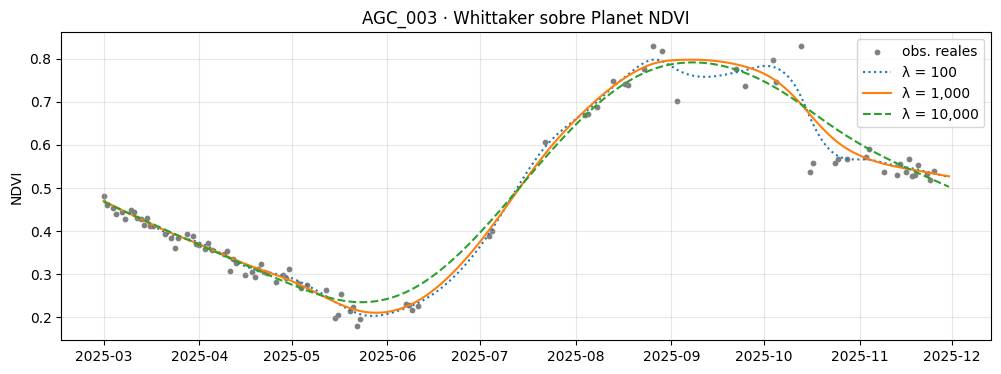

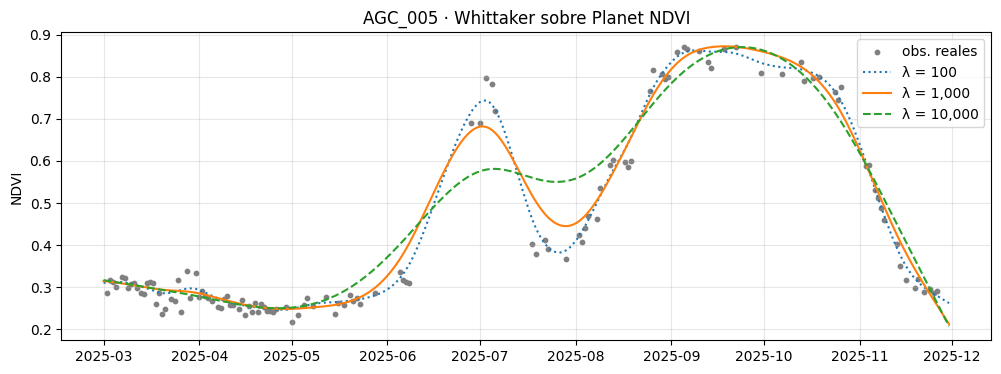

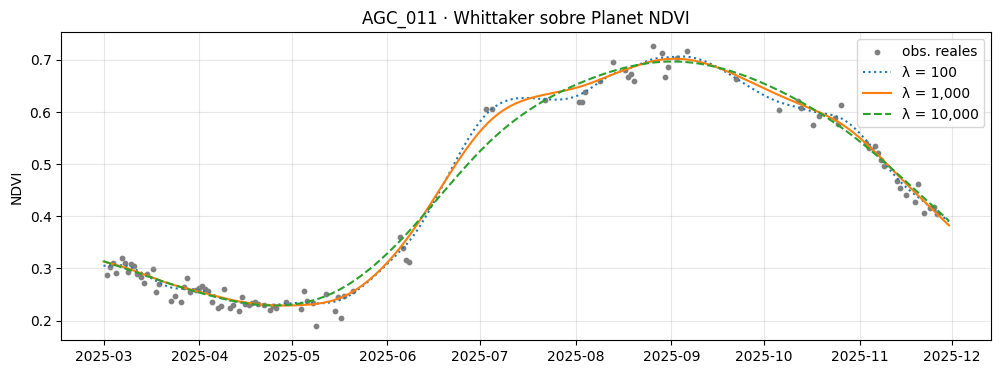

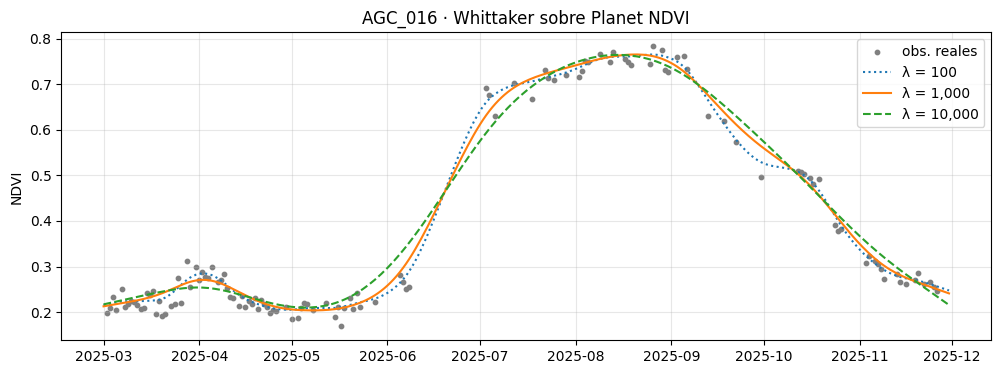

In [ ]:
#Suavizado Whittaker del NDVI de Planet sobre una malla diaria.
DIAS: pd.DatetimeIndex = pd.date_range(INICIO_CICLO, FIN_CICLO, freq="D")   # 275 días
LAMBDAS_PRUEBA: tuple[float, ...] = (100.0, 1_000.0, 10_000.0)
def matriz_penalizacion(n: int) -> sparse.csc_matrix:
    """D'D de segundas diferencias: penaliza los cambios bruscos de pendiente."""
    d = sparse.diags([1.0, -2.0, 1.0], [0, 1, 2], shape=(n - 2, n))
    return (d.T @ d).tocsc()
PENALIZACION = matriz_penalizacion(len(DIAS))   # se calcula una vez: la malla es la misma para todas

def whittaker(y: np.ndarray, pesos: np.ndarray, lam: float) -> np.ndarray:
    """Resuelve (W + λ·D'D) z = W·y. Los días sin dato tienen peso 0 y la curva los rellena."""
    w = sparse.diags(pesos)
    return spsolve((w + lam * PENALIZACION).tocsc(), pesos * np.nan_to_num(y))

def suavizar_parcela(
    grupo: pd.DataFrame,
    col: str,
    lam: float,
    iter_envolvente: int = 2,
    peso_bajo: float = 0.5,)
    real = grupo.loc[~grupo["es_descartado"]].set_index("fecha_captura")[col]
    y = real.reindex(DIAS).to_numpy(dtype=float)
    es_real = np.isfinite(y)
    pesos = es_real.astype(float)
    z = whittaker(y, pesos, lam)
    for _ in range(iter_envolvente):
        bajo_curva = es_real & (y < z)
        pesos = np.where(bajo_curva, peso_bajo, es_real.astype(float))
        z = whittaker(y, pesos, lam)

    return pd.DataFrame({"fecha": DIAS, "valor_ws": z, "es_obs_real": es_real})


def suavizar_todas(serie: pd.DataFrame, col: str, lam: float)
    partes = []
    for pid, grupo in serie.groupby(CLAVE, sort=True):
        curva = suavizar_parcela(grupo, col, lam)
        curva.insert(0, CLAVE, pid)
        partes.append(curva)
    return pd.concat(partes, ignore_index=True)


#Error contra las observaciones reales, NDVI máximo y fecha del pico por parcela
def metricas_suavizado(curvas: pd.DataFrame, serie: pd.DataFrame, col: str)

    reales = serie.loc[~serie["es_descartado"], [CLAVE, "fecha_captura", col]]
    unido = reales.merge(curvas, left_on=[CLAVE, "fecha_captura"], right_on=[CLAVE, "fecha"],
                         how="inner", validate="one_to_one")
    error = unido.assign(res=unido[col] - unido["valor_ws"]).groupby(CLAVE)["res"]
    ciclo = curvas[curvas["fecha"].between("2025-04-01", "2025-10-31")]
    idx_pico = ciclo.groupby(CLAVE)["valor_ws"].idxmax()
    return pd.DataFrame({
        "rmse": error.apply(lambda r: float(np.sqrt((r ** 2).mean()))),
        "sesgo": error.mean(),                       # > 0: la curva queda por debajo de los datos
        "ndvi_max": ciclo.groupby(CLAVE)["valor_ws"].max(),
        "fecha_pico": ciclo.loc[idx_pico.to_numpy()].set_index(CLAVE)["fecha"],})


# Comparación de λ.
curvas_por_lambda: dict[float, pd.DataFrame] = {}
metricas_por_lambda: dict[float, pd.DataFrame] = {}
for lam in LAMBDAS_PRUEBA:
    curvas_por_lambda[lam] = suavizar_todas(pl, "pl_ndvi_promedio", lam)
    metricas_por_lambda[lam] = metricas_suavizado(curvas_por_lambda[lam], pl, "pl_ndvi_promedio")

for lam, curvas in curvas_por_lambda.items():
    assert len(curvas) == 197 * len(DIAS), f"λ={lam}: filas incorrectas"
    assert curvas["valor_ws"].notna().all(), f"λ={lam}: curva con NaN"

resumen = pd.DataFrame({
    lam: {
        "rmse_mediana": m["rmse"].median(),
        "rmse_p90": m["rmse"].quantile(0.9),
        "sesgo_mediana": m["sesgo"].median(),
        "ndvi_max_mediana": m["ndvi_max"].median(),
    }
    for lam, m in metricas_por_lambda.items()
}).round(4)
print("Comparación de λ:\n", resumen, "\n")

ref = metricas_por_lambda[1_000.0]
for lam in (100.0, 10_000.0):
    m = metricas_por_lambda[lam]
    dif_pico = (m["fecha_pico"] - ref["fecha_pico"]).dt.days.abs()
    print(f"λ={lam:>7,.0f} vs 1,000 | Δndvi_max mediana: "
          f"{(m['ndvi_max'] - ref['ndvi_max']).abs().median():.3f} | "
          f"pico movido > 7 días: {int((dif_pico > 7).sum())} parcelas")

def graficar_lambdas(pid: str)
    _, ax = plt.subplots(figsize=(12, 4))
    obs = pl[(pl[CLAVE] == pid) & ~pl["es_descartado"]]
    ax.scatter(obs["fecha_captura"], obs["pl_ndvi_promedio"], s=10, color="0.5", label="obs. reales")
    for lam, estilo in zip(LAMBDAS_PRUEBA, (":", "-", "--")):
        c = curvas_por_lambda[lam]
        c = c[c[CLAVE] == pid]
        ax.plot(c["fecha"], c["valor_ws"], ls=estilo, lw=1.5, label=f"λ = {lam:,.0f}")
    ax.set_title(f"{pid} · Whittaker sobre Planet NDVI")
    ax.set_ylabel("NDVI")
    ax.grid(alpha=0.3)
    ax.legend()
    plt.show()

for pid in ("AGC_003", "AGC_005", "AGC_011", "AGC_016"):
    graficar_lambdas(pid)

### Elección del parámetro de suavizado $\lambda$

**Decisión**: se compararon $\lambda \in \{100,\ 1{,}000,\ 10{,}000\}$ y se eligió $\lambda = 1{,}000$.


**Interpretaciones de graficos, por visualizacion y la tabla**

- **Error contra las observaciones reales**: el RMSE mediano crece con $\lambda$ ($0.0189$, $0.0232$ y $0.0312$), y el percentil 90 pasa de $0.0233$ a $0.0479$. Con $\lambda = 10{,}000$ la curva se aleja notablemente de los datos en el 10 % de las parcelas peor ajustadas.
- **Sesgo**: el residuo mediano ($y - z$) es negativo en los tres casos ($-0.0049$ a $-0.0075$). La curva queda en promedio ligeramente **por encima** de las observaciones, que es el efecto esperado de la envolvente superior.
- **Altura del pico**: el NDVI máximo mediano baja de $0.749$ a $0.734$ al pasar de $\lambda = 100$ a $10{,}000$. Un suavizado excesivo recorta el pico.
- **Estabilidad de la fecha del pico (`argmax`)**: entre $\lambda = 100$ y $1{,}000$ el pico se mueve más de 7 días en $35$ parcelas, y entre $10{,}000$ y $1{,}000$ en $42$.
- **Decisión**: $\lambda = 1{,}000$ porque no minimiza el RMSE
**Limitaciones y supuestos pendientes**
- $\lambda$ se eligió entre tres valores por inspección, sin un criterio de optimización. Existen criterios formales como la validación cruzada o las curvas L y V (Eilers, 2003; Frasso y Eilers, 2015), aunque Cai et al. (2017) advierten que la validación cruzada puede producir malos ajustes en algunos casos.

--------------------------------------------------------------------------

# Diagnóstico de la inestabilidad del pico

si la fecha del pico se toma como el día de NDVI máximo (`argmax`), cambia más de una semana en decenas de parcelas con solo variar $\lambda$. Una variable tan sensible a un parámetro de preprocesamiento no es confiable como predictor.

**Posible hipotesis**: cuando la curva forma una **meseta** larga, varios días tienen un NDVI casi igual al máximo, y un cambio pequeño en el suavizado basta para mover el día exacto del máximo.

In [ ]:
LAMBDA_ELEGIDO: float = 1_000.0
curvas = curvas_por_lambda[LAMBDA_ELEGIDO]
ciclo = curvas[curvas["fecha"].between("2025-04-01", "2025-10-31")]
maximo = ciclo.groupby(CLAVE)["valor_ws"].transform("max")
dias_meseta = (ciclo["valor_ws"] >= maximo - 0.02).groupby(ciclo[CLAVE]).sum()   # días a ≤ 0.02 del máximo
m100, m1k, m10k = (metricas_por_lambda[l] for l in LAMBDAS_PRUEBA)
salto = pd.concat([
    (m100["fecha_pico"] - m1k["fecha_pico"]).dt.days.abs(),
    (m10k["fecha_pico"] - m1k["fecha_pico"]).dt.days.abs(),
], axis=1).max(axis=1)
inestable = salto > 7
print("Días de meseta (a ≤ 0.02 del máximo):")
print(pd.DataFrame({"estables": dias_meseta[~inestable].describe(),
                    "inestables": dias_meseta[inestable].describe()}).round(1).T
      [["count", "min", "50%", "max"]])
print("\nParcelas inestables con más saltos:", salto.sort_values(ascending=False).head(6).to_dict())

Días de meseta (a ≤ 0.02 del máximo):
            count   min   50%   max
estables    133.0  13.0  24.0  68.0
inestables   64.0  14.0  32.5  62.0

Parcelas inestables con más saltos: {'AGC_194': 91, 'AGC_168': 82, 'AGC_066': 67, 'AGC_186': 60, 'AGC_010': 59, 'AGC_185': 57}


**Interpretaciones**
- **Comportamiento**: las parcelas inestables tienen mesetas más largas (mediana de $32.5$ días frente a $24$). Los rangos se traslapan ($13$–$68$ y $14$–$62$), así que la meseta explica parte de la inestabilidad pero no toda.
- **Casos extremos**: los saltos de `AGC_194` ($91$ días), `AGC_168` ($82$) y `AGC_066` ($67$) son demasiado grandes para venir de una meseta. Corresponden a curvas con **dos máximos de altura parecida**, donde el `argmax` salta de uno a otro

## Detección del ciclo productivo y métricas fenológicas

**Problemas**: que en algunas parcelas la curva tiene más de un ciclo de verdor dentro de la ventana, por ejemplo por maleza antes de la siembra, rebrote o un segundo cultivo. Hay que decidir cuál es el ciclo de la cebada y medir sus fechas lo mejor posible para no andar a ciegas.
investigando ciertos posibles determinantes

1. **Detección de ciclos** con `scipy.signal.find_peaks` (Virtanen et al., 2020). Un pico cuenta como ciclo si su **prominencia** es al menos $0.15$ de NDVI y si está a más de **30 días** de otro pico. La prominencia es la distancia vertical entre el pico y su línea de contorno más baja (SciPy, s. f.). A diferencia de la altura absoluta, mide cuánto destaca el pico sobre su entorno. Cada ciclo se delimita entre los mínimos que lo rodean.
2. **Regla del ciclo productivo**: si hay más de un ciclo, se elige el de **mayor área** sobre su línea base. El área integra la altura y la duración, y es más robusta que tomar el pico más alto. Si el segundo ciclo tiene al menos el **70 %** del área del primero, se marca `diag_ciclo_ambiguo`.
3. **Fechas por umbrales de amplitud**, medidos por separado desde el mínimo izquierdo (subida) y el derecho (bajada):
   - `sos20` y `eos20`: 20 % de la amplitud, como inicio y fin del verdor.
   - `sos50` y `eos50`: 50 %, como punto medio de la subida y de la bajada.
   - 80 %: se usa para calcular las tasas de subida y de bajada.
   - 90 %: define la **meseta**, el tramo continuo alrededor del pico que no baja de ese nivel. Su centro es `pl_centro_pico_doy`.
4. **Métricas derivadas**: NDVI del pico, base y amplitud; integral del ciclo entre `sos20` y `eos20` sobre la línea base; tasas de subida y de bajada; caída intra-ciclo (el mayor descenso respecto al máximo previo antes del pico); y `pl_hueco_max_critico`, el hueco más largo sin observación real entre `sos20` y el pico.
5. **Variables de ventana fija establecida en el reto** (abril a octubre): máximo, integral y media del NDVI. No dependen de la detección del ciclo y sirven de respaldo si esa detección falla.

**Justificación**
- Definir el inicio y el fin de la temporada como el momento en que la curva alcanza una **fracción de la amplitud estacional**, medida desde el mínimo de cada lado, es el método de TIMESAT (Jönsson y Eklundh, 2004). Al normalizar por amplitud, el umbral se adapta a cada parcela y no depende del nivel absoluto de NDVI del suelo. 
- La integral del NDVI, las tasas de reverdecimiento y de senescencia, el NDVI máximo y su fecha son métricas fenológicas clásicas (Reed et al., 1994), y la revisión de Zeng et al. (2020) las sigue considerando métricas estándar.
- El centro de la meseta reemplaza al `argmax` por evidencia pasada

In [ ]:
#Ciclos de verdor, regla del ciclo productivo y métricas fenológicas
from scipy.signal import find_peaks
PROMINENCIA_MIN: float = 0.15 # la misma de la exploración de antes del 2
DIST_MIN_DIAS: int = 30  # dos picos a menos de un mes son el mismo ciclo
UMBRAL_INICIO, UMBRAL_MITAD, UMBRAL_RAPIDO, UMBRAL_MESETA = 0.20, 0.50, 0.80, 0.90
RATIO_AMBIGUO: float = 0.70  # 2.º ciclo con ≥ 70 % del área del 1.º → elección dudosa
VENTANA_FIJA = (pd.Timestamp("2025-04-01"), pd.Timestamp("2025-10-31"))


def _primer_cruce(v: np.ndarray, umbral: float, desde: int, hasta: int) -> int:
    """Primer índice en [desde, hasta] con v ≥ umbral (subida)."""
    idx = np.arange(desde, hasta + 1)
    return int(idx[v[idx] >= umbral][0])


def _ultimo_cruce(v: np.ndarray, umbral: float, desde: int, hasta: int) -> int:
    """Último índice en [desde, hasta] con v ≥ umbral (bajada)."""
    idx = np.arange(desde, hasta + 1)
    return int(idx[v[idx] >= umbral][-1])


def detectar_ciclos(v: np.ndarray, prominencia: float = PROMINENCIA_MIN) -> list[dict[str, float | int]]:
    """Picos con prominencia suficiente; cada ciclo va del mínimo previo al siguiente."""
    picos, _ = find_peaks(v, prominence=prominencia, distance=DIST_MIN_DIAS)
    if picos.size == 0:
        return []
    cortes = [0] + [int(a + np.argmin(v[a:b + 1])) for a, b in zip(picos[:-1], picos[1:])] + [len(v) - 1]
    ciclos = []
    for k, p in enumerate(picos):
        lo, hi = cortes[k], cortes[k + 1]
        i_bl = int(lo + np.argmin(v[lo:p + 1]))
        i_br = int(p + np.argmin(v[p:hi + 1]))
        base = max(v[i_bl], v[i_br])
        area = float(np.clip(v[i_bl:i_br + 1] - base, 0, None).sum())
        ciclos.append({"pico": int(p), "i_bl": i_bl, "i_br": i_br, "area": area})
    return ciclos


def fenologia_parcela(
    v: np.ndarray, obs_real: np.ndarray, prominencia: float = PROMINENCIA_MIN
) -> dict[str, float]:
    """Métricas del ciclo productivo de una curva diaria suavizada.

    Args:
        v: Curva diaria (Whittaker) en la ventana marzo–noviembre.
        obs_real: Máscara de los días con observación real.

    Returns:
        Diccionario de métricas (fechas como día del año) y banderas de calidad.
    """
    ciclos = detectar_ciclos(v, prominencia)
    res: dict[str, float] = {"pl_n_picos": len(ciclos)}
    if not ciclos:
        return res | {"diag_sin_ciclo": True, "diag_ciclo_ambiguo": False}

    areas = sorted((c["area"] for c in ciclos), reverse=True)
    c = max(ciclos, key=lambda x: x["area"])                 # regla del ciclo productivo
    p, i_bl, i_br = c["pico"], c["i_bl"], c["i_br"]
    bl, br = v[i_bl], v[i_br]
    amp_l, amp_r = v[p] - bl, v[p] - br

    sos20 = _primer_cruce(v, bl + UMBRAL_INICIO * amp_l, i_bl, p)
    sos50 = _primer_cruce(v, bl + UMBRAL_MITAD * amp_l, i_bl, p)
    sos80 = _primer_cruce(v, bl + UMBRAL_RAPIDO * amp_l, i_bl, p)
    eos80 = _ultimo_cruce(v, br + UMBRAL_RAPIDO * amp_r, p, i_br)
    eos50 = _ultimo_cruce(v, br + UMBRAL_MITAD * amp_r, p, i_br)
    eos20 = _ultimo_cruce(v, br + UMBRAL_INICIO * amp_r, p, i_br)

       # Meseta = tramo CONTINUO alrededor del pico (no todos los días altos del ciclo).
    umbral_meseta = v[p] - (1 - UMBRAL_MESETA) * min(amp_l, amp_r)
    ini = fin = p
    while ini > sos50 and v[ini - 1] >= umbral_meseta:
        ini -= 1
    while fin < eos50 and v[fin + 1] >= umbral_meseta:
        fin += 1
    centro = (ini + fin) // 2

    # caida intra-ciclo: mayor descenso respecto al máximo previo entre el inicio y el pico captura un valle que no llega a separar dos ciclos (estrés, canícula, labor).
    tramo = v[sos20:p + 1]
    caida_intra = float((np.maximum.accumulate(tramo) - tramo).max())

    # Hueco más largo sin observación real entre el inicio de verdor y el pico (emergencia).
    reales = np.flatnonzero(obs_real[sos20:p + 1]) + sos20
    hueco = int(np.diff(np.r_[sos20, reales, p]).max()) if p > sos20 else 0

    doy = lambda i: int(DIAS[i].dayofyear)
    return res | {
        "pl_sos20_doy": doy(sos20), "pl_sos50_doy": doy(sos50),
        "pl_centro_pico_doy": doy(centro),
        "pl_eos50_doy": doy(eos50), "pl_eos20_doy": doy(eos20),
        "pl_duracion_dias": eos20 - sos20,
        "pl_dias_meseta": int(fin - ini + 1),
        "pl_caida_intra_ciclo": caida_intra,
        "pl_ndvi_pico": float(v[p]), "pl_ndvi_base": float((bl + br) / 2),
        "pl_amplitud": float(v[p] - (bl + br) / 2),
        "pl_integral_ciclo": float(np.clip(v[sos20:eos20 + 1] - (bl + br) / 2, 0, None).sum()),
        "pl_tasa_subida": float((UMBRAL_RAPIDO - UMBRAL_INICIO) * amp_l / max(sos80 - sos20, 1)),
        "pl_tasa_bajada": float((UMBRAL_RAPIDO - UMBRAL_INICIO) * amp_r / max(eos20 - eos80, 1)),
        "pl_hueco_max_critico": hueco,
        "diag_sin_ciclo": False,
        "diag_ciclo_ambiguo": len(areas) > 1 and areas[1] / areas[0] >= RATIO_AMBIGUO,
    }


def tabla_fenologia(curvas: pd.DataFrame, prominencia: float = PROMINENCIA_MIN) -> pd.DataFrame:
    """Una fila por parcela: métricas del ciclo productivo + variables de ventana fija."""
    filas = []
    for pid, c in curvas.groupby(CLAVE, sort=True):
        filas.append({CLAVE: pid, **fenologia_parcela(c["valor_ws"].to_numpy(),
                                                      c["es_obs_real"].to_numpy(),
                                                      prominencia)})
    feno = pd.DataFrame(filas)

    fija = curvas[curvas["fecha"].between(*VENTANA_FIJA)].groupby(CLAVE)["valor_ws"]
    feno = feno.merge(
        pd.DataFrame({"pl_ndvi_max_abr_oct": fija.max(),
                      "pl_ndvi_int_abr_oct": fija.sum(),
                      "pl_ndvi_media_abr_oct": fija.mean()}).reset_index(),
        on=CLAVE, how="left", validate="one_to_one",
    )
    return feno


feno_pl = tabla_fenologia(curvas_por_lambda[LAMBDA_ELEGIDO])

# Contratos.
assert len(feno_pl) == 197 and feno_pl[CLAVE].is_unique
assert feno_pl[["pl_ndvi_max_abr_oct", "pl_ndvi_int_abr_oct"]].notna().all().all()
con_ciclo = ~feno_pl["diag_sin_ciclo"]
assert (feno_pl.loc[con_ciclo, "pl_sos20_doy"] <= feno_pl.loc[con_ciclo, "pl_sos50_doy"]).all()
assert (feno_pl.loc[con_ciclo, "pl_sos50_doy"] <= feno_pl.loc[con_ciclo, "pl_centro_pico_doy"]).all()
assert (feno_pl.loc[con_ciclo, "pl_centro_pico_doy"] <= feno_pl.loc[con_ciclo, "pl_eos50_doy"]).all()
assert (feno_pl.loc[con_ciclo, "pl_eos50_doy"] <= feno_pl.loc[con_ciclo, "pl_eos20_doy"]).all()

print("Picos por parcela:", feno_pl["pl_n_picos"].value_counts().sort_index().to_dict())
print("Sin ciclo:", int(feno_pl["diag_sin_ciclo"].sum()),
      "| ciclo ambiguo:", int(feno_pl["diag_ciclo_ambiguo"].sum()), "\n")
print(feno_pl.loc[con_ciclo].describe().round(2).T[["min", "25%", "50%", "75%", "max"]])

Picos por parcela: {1: 178, 2: 19}
Sin ciclo: 0 | ciclo ambiguo: 1 

                          min     25%     50%     75%     max
pl_n_picos               1.00    1.00    1.00    1.00    2.00
pl_sos20_doy           147.00  157.00  163.00  170.00  237.00
pl_sos50_doy           161.00  173.00  184.00  207.00  247.00
pl_centro_pico_doy     186.00  230.00  247.00  260.00  286.00
pl_eos50_doy           257.00  287.00  301.00  308.00  320.00
pl_eos20_doy           288.00  311.00  318.00  322.00  328.00
pl_duracion_dias        88.00  140.00  154.00  163.00  175.00
pl_dias_meseta          14.00   34.00   38.00   48.00   86.00
pl_caida_intra_ciclo     0.00    0.00    0.00    0.01    0.14
pl_ndvi_pico             0.53    0.69    0.75    0.79    0.89
pl_ndvi_base             0.17    0.22    0.24    0.28    0.47
pl_amplitud              0.29    0.44    0.49    0.54    0.68
pl_integral_ciclo       20.70   44.69   50.24   55.66   70.34
pl_tasa_subida           0.00    0.01    0.01    0.01    0.02
p

## Robustez de las fechas fenológicas ante $\lambda$
esto deriva de los resultados en la tabla anterior
**Objetivo**: se busco comprobar que las fechas por umbral y el centro de la meseta son **menos sensibles** a $\lambda$ que el `argmax` original, que movía el pico más de 7 días en 35 parcelas ($\lambda = 100$) y en 42 ($\lambda = 10{,}000$).

se recalcula la tabla fenológica con $\lambda = 100$ y con $\lambda = 10{,}000$, y se cuentan las parcelas cuyo `sos50`, centro del pico o `eos50` cambia más de 7 días respecto a $\lambda = 1{,}000$. Probar la sensibilidad de las métricas al método de suavizado es una recomendación de las investigaciones, porque la elección del suavizado altera las métricas fenológicas (Cai et al., 2017; Zeng et al., 2020).


λ=    100 vs 1,000 | parcelas con salto > 7 días: {'pl_sos50_doy': 23, 'pl_centro_pico_doy': 22, 'pl_eos50_doy': 3} | cambio en n_picos: 22
λ= 10,000 vs 1,000 | parcelas con salto > 7 días: {'pl_sos50_doy': 46, 'pl_centro_pico_doy': 11, 'pl_eos50_doy': 10} | cambio en n_picos: 18


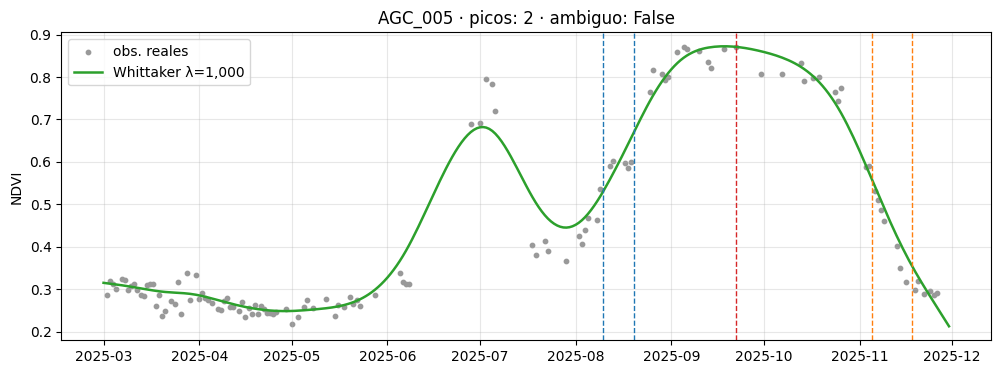

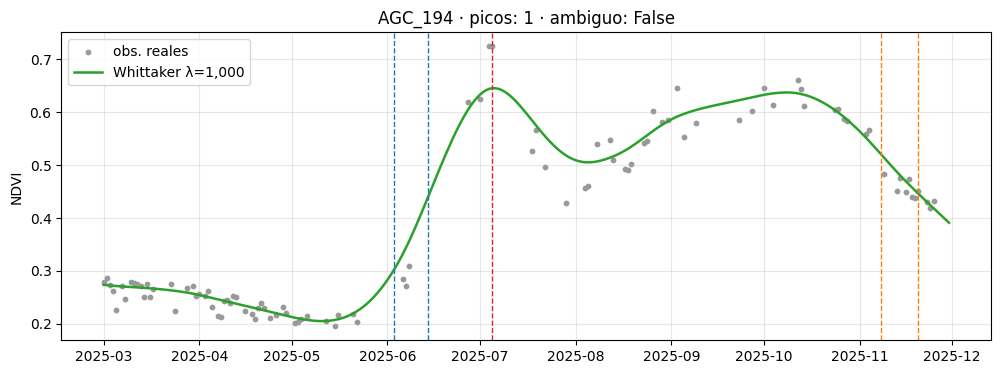

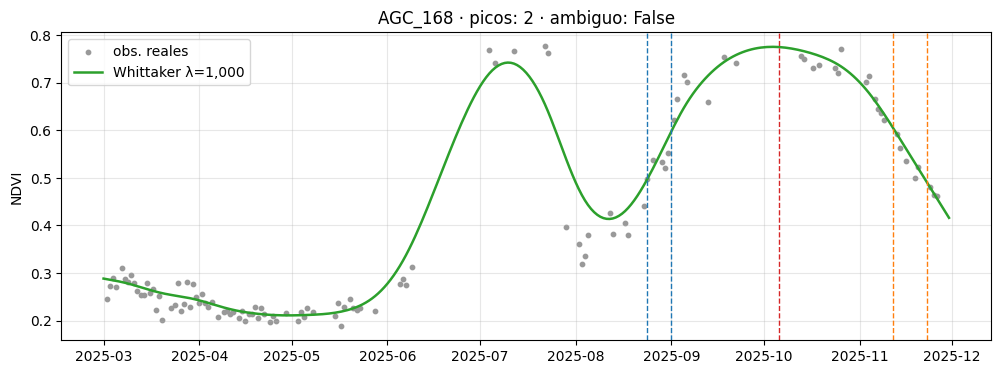

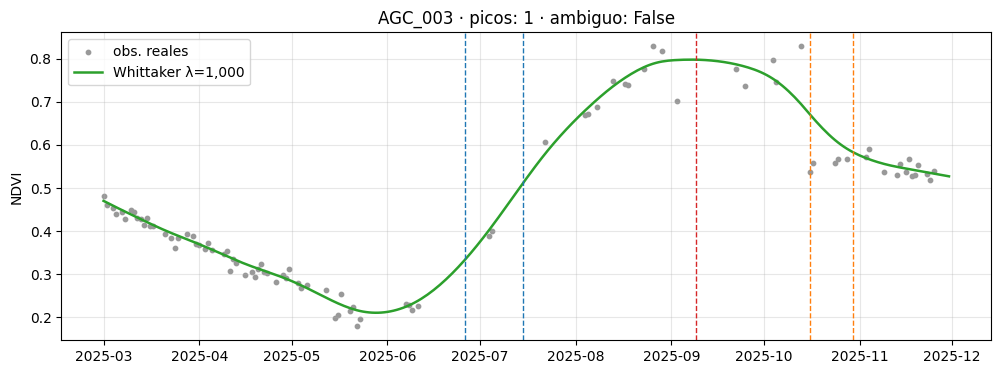

In [ ]:
# Robustez de las fechas ante λ: argmax tenía 35 y 42 parcelas con saltos > 7 días.
COLS_FECHA = ["pl_sos50_doy", "pl_centro_pico_doy", "pl_eos50_doy"]
ref = feno_pl.set_index(CLAVE)
for lam in (100.0, 10_000.0):
    alt = tabla_fenologia(curvas_por_lambda[lam]).set_index(CLAVE)
    salto = (alt[COLS_FECHA] - ref[COLS_FECHA]).abs()
    print(f"λ={lam:>7,.0f} vs 1,000 | parcelas con salto > 7 días:",
          {c: int((salto[c] > 7).sum()) for c in COLS_FECHA},
          "| cambio en n_picos:", int((alt["pl_n_picos"] != ref["pl_n_picos"]).sum()))


def graficar_fenologia(pid: str) -> None:
    """Curva, observaciones reales y fechas fenológicas del ciclo elegido."""
    c = curvas_por_lambda[LAMBDA_ELEGIDO]
    c = c[c[CLAVE] == pid]
    f = ref.loc[pid]
    _, ax = plt.subplots(figsize=(12, 4))
    ax.scatter(c.loc[c["es_obs_real"], "fecha"],
               pl.set_index([CLAVE, "fecha_captura"]).loc[pid].reindex(c.loc[c["es_obs_real"], "fecha"])
               ["pl_ndvi_promedio"], s=10, color="0.6", label="obs. reales")
    ax.plot(c["fecha"], c["valor_ws"], color="tab:green", lw=1.8, label="Whittaker λ=1,000")
    if not f["diag_sin_ciclo"]:
        for col, color in (("pl_sos20_doy", "tab:blue"), ("pl_sos50_doy", "tab:blue"),
                           ("pl_centro_pico_doy", "tab:red"),
                           ("pl_eos50_doy", "tab:orange"), ("pl_eos20_doy", "tab:orange")):
            ax.axvline(pd.Timestamp("2025-01-01") + pd.Timedelta(days=int(f[col]) - 1),
                       color=color, ls="--", lw=1)
    ax.set_title(f"{pid} · picos: {int(f['pl_n_picos'])} · ambiguo: {bool(f['diag_ciclo_ambiguo'])}")
    ax.set_ylabel("NDVI")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left")
    plt.show()


for pid in ("AGC_005", "AGC_194", "AGC_168", "AGC_003"):
    graficar_fenologia(pid)

**Interpretaciones**

- **Centro del pico**: las parcelas con salto mayor a 7 días bajan de $35$ a $22$ ($\lambda = 100$) y de $42$ a $11$ ($\lambda = 10{,}000$). El centro de la meseta es más robusto que el `argmax`.
- **Fin del ciclo (`eos50`)**: es la fecha más estable ($3$ y $10$ parcelas).
- **Inicio del ciclo (`sos50`)**: sigue siendo sensible, sobre todo con $\lambda = 10{,}000$ ($46$ parcelas). Un suavizado fuerte deforma la subida, que es el tramo donde hay menos observaciones (ver `pl_hueco_max_critico`).
- **Número de picos**: `pl_n_picos` cambia en $22$ y $18$ parcelas. Es la métrica más dependiente del preprocesamiento.

**Limitaciones**: `pl_n_picos` y `pl_sos50_doy` entran al modelo como features. Su sensibilidad a $\lambda$ conviene tenerla en cuenta al interpretar su importancia en el modelo.

### Sensibilidad a la prominencia mínima

 Antes de fijar la prominencia conviene comprobar si un umbral menos exigente ($0.10$) cambia las métricas o la elección del ciclo productivo. por lo que se busca generar las dos versiones de la tabla y comparar el número de parcelas con dos o más picos, las parcelas ambiguas (en total y en `PREDICCION`), la duración, el inicio y la caída intra-ciclo.


                      0.15   0.10
parcelas_2+_picos     19.0   30.0
ambiguas               1.0    1.0
ambiguas_PREDICCION    1.0    1.0
duracion_mediana     154.0  151.0
duracion_p90         168.0  167.0
sos20_mediana_doy    163.0  164.0
caida_intra_p90        0.1    0.0 

Parcelas cuyo inicio cambia con 0.10: 11 → {'ENTRENAMIENTO': 9, 'PREDICCION': 2}


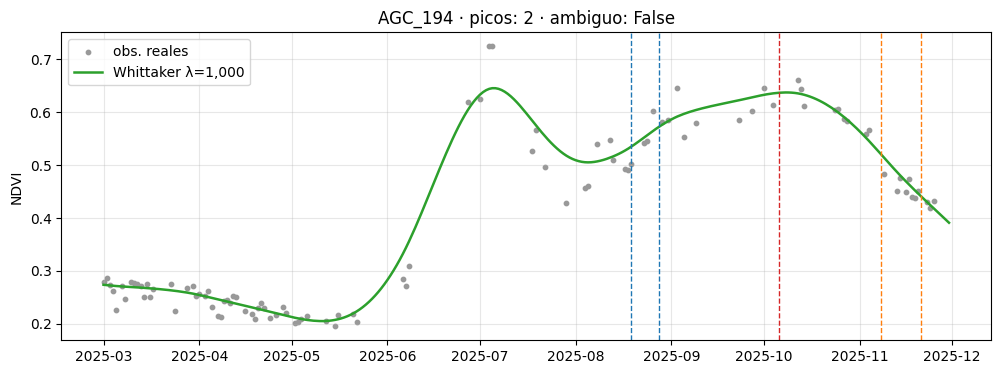

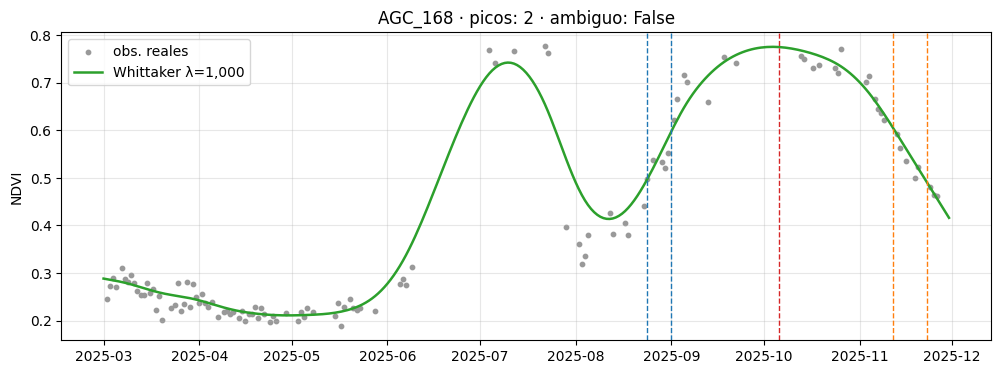

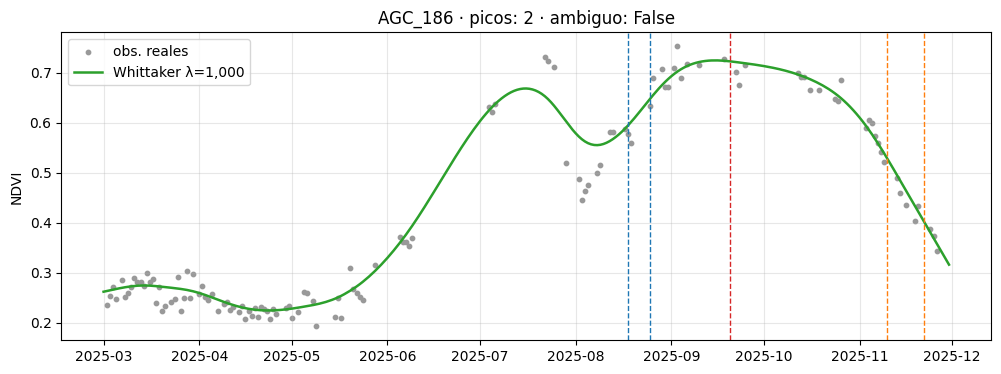

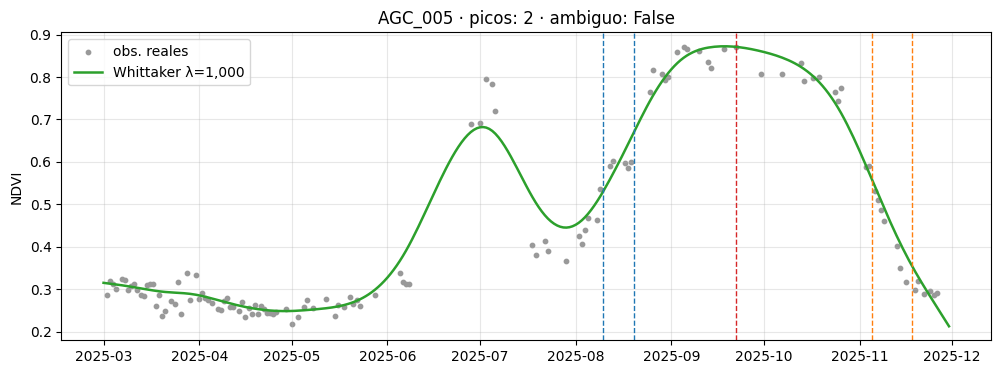

In [ ]:
# Prominencia 0.15 vs 0.10 sobre la curva suavizada (comparar antes de cambiar).
curvas_ref = curvas_por_lambda[LAMBDA_ELEGIDO]
versiones_prom = {p: tabla_fenologia(curvas_ref, p).set_index(CLAVE) for p in (0.15, 0.10)}

conjunto = parcelas.set_index(CLAVE)["conjunto"]
resumen_prom = pd.DataFrame({
    p: {
        "parcelas_2+_picos": int((f["pl_n_picos"] >= 2).sum()),
        "ambiguas": int(f["diag_ciclo_ambiguo"].sum()),
        "ambiguas_PREDICCION": int((f["diag_ciclo_ambiguo"] & conjunto.eq("PREDICCION")).sum()),
        "duracion_mediana": f["pl_duracion_dias"].median(),
        "duracion_p90": f["pl_duracion_dias"].quantile(0.9),
        "sos20_mediana_doy": f["pl_sos20_doy"].median(),
        "caida_intra_p90": f["pl_caida_intra_ciclo"].quantile(0.9),
    }
    for p, f in versiones_prom.items()
}).round(1)
print(resumen_prom, "\n")

cambia = versiones_prom[0.15]["pl_sos20_doy"] != versiones_prom[0.10]["pl_sos20_doy"]
print(f"Parcelas cuyo inicio cambia con 0.10: {int(cambia.sum())} → "
      f"{conjunto[cambia[cambia].index].value_counts().to_dict()}")

# Gráficas con la versión 0.10 (reasigna 'ref', que usa graficar_fenologia).
ref = versiones_prom[0.10]
for pid in ("AGC_194", "AGC_168", "AGC_186", "AGC_005"):
    graficar_fenologia(pid)

**Interpretaciones**

- **Número de picos**: con $0.10$, las parcelas con dos o más picos pasan de $19$ a $30$. El umbral más bajo cuenta como ciclo ondulaciones menores.
- **Ciclo elegido**: casi no cambia. Las parcelas ambiguas siguen siendo $1$ (de `PREDICCION`), la duración mediana pasa de $154$ a $151$ días y el `sos20` mediano de $163$ a $164$.
- **Parcelas afectadas**: el inicio cambia en $11$ parcelas ($9$ de entrenamiento y $2$ de predicción).
- **Decisión**: se conserva **$0.15$**, que es el valor que usa la celda 4.3 para generar la tabla que se guarda. Bajar el umbral agrega picos sin mejorar la elección del ciclo.

### Fenología de Sentinel-2 y bandera de discrepancia

**Decisión**: a Sentinel-2 se le aplica el mismo procedimiento que a Planet (Whittaker con $\lambda = 1{,}000$ y prominencia de $0.15$) y sus columnas se guardan con prefijo `s2_`. Si `sos50` o el centro del pico difieren entre sensores en **más de 15 días**, se marca `diag_fenologia_discrepante`.

**Justificación**: estimar la misma métrica con dos sensores independientes permite detectar parcelas donde alguna de las dos estimaciones falla. Moon et al. (2021) reportan alta concordancia y sesgo despreciable entre las métricas de PlanetScope y de Landsat/Sentinel-2, de modo que una discrepancia grande indica un problema de datos más que una diferencia esperada entre sensores. El umbral de 15 días es un **criterio práctico**: equivale a unas 2.5 veces el intervalo medio entre observaciones reales de Sentinel-2 ($\approx 5.9$ días).


In [ ]:
# LAI del ciclo productivo, contraste con Sentinel-2 y guardado de la fenología.
UMBRAL_DISCREPANCIA_DIAS: int = 15

curvas_pl = curvas_por_lambda[LAMBDA_ELEGIDO]
feno_pl = tabla_fenologia(curvas_pl, PROMINENCIA_MIN)

def a_sensor(df: pd.DataFrame, prefijo: str) -> pd.DataFrame:
    """Renombra pl_* → {prefijo}* y diag_* → diag_{prefijo}* (las funciones usan pl_ por defecto)."""
    def nuevo(c: str) -> str:
        if c.startswith("pl_"):
            return prefijo + c.removeprefix("pl_")
        if c.startswith("diag_"):
            return f"diag_{prefijo}" + c.removeprefix("diag_")
        return c
    return df.rename(columns=nuevo)

def integrar_en_ciclo(curvas: pd.DataFrame, feno: pd.DataFrame, nombre: str) -> pd.DataFrame:
    """Máximo e integral de una curva diaria entre sos20 y eos20 de cada parcela."""
    ventana = curvas.assign(doy=curvas["fecha"].dt.dayofyear).merge(
        feno[[CLAVE, "pl_sos20_doy", "pl_eos20_doy"]], on=CLAVE, how="left", validate="many_to_one"
    )
    en_ciclo = ventana[ventana["doy"].between(ventana["pl_sos20_doy"], ventana["pl_eos20_doy"])]
    return (en_ciclo.groupby(CLAVE)["valor_ws"]
            .agg(**{f"{nombre}_max_ciclo": "max", f"{nombre}_int_ciclo": "sum"})
            .reset_index())


#LAI de Planet: suavizado, recortado a ≥ 0 e integrado en el ciclo del NDVI.
curvas_lai = suavizar_todas(pl, "pl_lai_promedio", LAMBDA_ELEGIDO)
negativos = int((curvas_lai["valor_ws"] < 0).sum())
curvas_lai["valor_ws"] = curvas_lai["valor_ws"].clip(lower=0)
lai_ciclo = integrar_en_ciclo(curvas_lai, feno_pl, "pl_lai")
print(f"LAI: {negativos} días con valor negativo recortados a 0")

# Fenología de Sentinel-2 (mismo método, columnas s2_; nunca se mezcla con Planet).
curvas_s2 = suavizar_todas(s2_2025, "s2_ndvi_promedio", LAMBDA_ELEGIDO)
feno_s2 = a_sensor(tabla_fenologia(curvas_s2, PROMINENCIA_MIN), "s2_")
COLS_S2_FENO = [CLAVE, "s2_n_picos", "s2_sos50_doy", "s2_centro_pico_doy", "s2_eos50_doy",
                "s2_ndvi_pico", "s2_integral_ciclo", "s2_ndvi_int_abr_oct", "diag_s2_sin_ciclo"]
feno_s2 = feno_s2[COLS_S2_FENO]

# Ensamble y concordancia de fechas entre sensores.
fenologia = (
    feno_pl
    .merge(lai_ciclo, on=CLAVE, how="left", validate="one_to_one")
    .merge(feno_s2, on=CLAVE, how="left", validate="one_to_one")
)
delta = pd.DataFrame({
    "sos50": fenologia["s2_sos50_doy"] - fenologia["pl_sos50_doy"],
    "centro_pico": fenologia["s2_centro_pico_doy"] - fenologia["pl_centro_pico_doy"],
    "eos50": fenologia["s2_eos50_doy"] - fenologia["pl_eos50_doy"],
})
fenologia["diag_fenologia_discrepante"] = (
    (delta[["sos50", "centro_pico"]].abs() > UMBRAL_DISCREPANCIA_DIAS).any(axis=1))

# Contratos
assert len(fenologia) == 197 and fenologia[CLAVE].is_unique
assert set(fenologia[CLAVE]) == set(parcelas[CLAVE])
assert (fenologia["pl_lai_max_ciclo"].dropna() >= 0).all(), "LAI negativo tras el recorte"
assert "rendimiento_t_ha" not in fenologia.columns, "Fuga: la fenología no puede contener y"

print("\nDiferencia de fechas S2 − Planet (días):")
print(delta.describe(percentiles=[0.1, 0.5, 0.9]).round(1).T[["10%", "50%", "90%"]])
print("\nDiscrepantes (> 15 días):", int(fenologia["diag_fenologia_discrepante"].sum()),
      "-->", fenologia.loc[fenologia["diag_fenologia_discrepante"], CLAVE]
      .map(parcelas.set_index(CLAVE)["conjunto"]).value_counts().to_dict())

# Guardado: tabla por parcela + curvas diarias
fenologia.to_parquet(DIR_INTERIM / "fenologia_parcela.parquet", index=False)
curvas_diarias = (
    curvas_pl.rename(columns={"valor_ws": "pl_ndvi_ws", "es_obs_real": "pl_obs_real"})
    .merge(curvas_lai[[CLAVE, "fecha", "valor_ws"]].rename(columns={"valor_ws": "pl_lai_ws"}),
           on=[CLAVE, "fecha"], how="left", validate="one_to_one")
)
assert len(curvas_diarias) == 197 * len(DIAS)
curvas_diarias.to_parquet(DIR_INTERIM / "curvas_diarias_pl.parquet", index=False)
print(f"\nGuardado: fenologia_parcela {fenologia.shape} | curvas_diarias_pl {curvas_diarias.shape}")

LAI: 0 días con valor negativo recortados a 0

Diferencia de fechas S2 − Planet (días):
             10%  50%  90%
sos50       -6.0  0.0  4.0
centro_pico -6.4 -1.0  4.0
eos50       -5.0 -2.0  1.0

Discrepantes (> 15 días): 29 → {'ENTRENAMIENTO': 24, 'PREDICCION': 5}

Guardado: fenologia_parcela (197, 33) | curvas_diarias_pl (54175, 5)


**Interpretaciones**

- **LAI**: ningún día tuvo un valor negativo. El recorte no cambió ningún dato y queda solo como protección.
- **Concordancia entre sensores (S2 − Planet)**: la mediana de la diferencia es de $0$ días en `sos50`, $-1$ en el centro del pico y $-2$ en `eos50`. El 80 % central de las parcelas está dentro de $\pm 6.4$ días. No hay sesgo sistemático entre sensores

In [ ]:
#  Ensamble preliminar del dataset maestro (v0): parcelas + topografía + fenología.
OBJETIVO: str = "rendimiento_t_ha"
COLS_IDENTIDAD: list[str] = [CLAVE, "municipio", "estado", "conjunto", "clima_pixel_id"]
COLS_PARCELA: list[str] = [CLAVE, "municipio", "estado", "conjunto", "area_ha_geod",
                           OBJETIVO, "diag_y_redondo", "diag_y_resolucion"]

# Columnas técnicas de calidad que NO llevan prefijo diag_: tampoco son features.
COLS_CALIDAD: set[str] = {
    "topo_cobertura_pix", "pend_cobertura_pix", "ratio_cobertura_area", "ratio_cobertura_pend",
    "z_pixel_clima_m", "pl_hueco_max_critico",}
# Para integrar una fuente nueva basta con agregar una línea aquí.
TABLAS_POR_PARCELA: dict[str, str] = {
    "topografia": "topo_parcela.parquet",
    "fenologia": "fenologia_parcela.parquet",
    "agroclima": "agroclima_parcela.parquet",   #
    "suelo": "soil_parcela.parquet",           +
    "era5": "era5_parcela.parquet",            
}

def ensamblar_maestro(dir_interim: Path, tablas: dict[str, str]) -> pd.DataFrame:
    """Une las tablas por parcela con contratos estrictos (una fila por parcela, sin choques)."""
    maestro = pd.read_parquet(dir_interim / "parcelas_base.parquet", columns=COLS_PARCELA)
    for nombre, archivo in tablas.items():
        tabla = pd.read_parquet(dir_interim / archivo)
        if not tabla[CLAVE].is_unique or len(tabla) != 197:
            raise ValueError(f"{nombre}: debe tener 197 filas únicas; tiene {len(tabla)}")
        choque = (set(tabla.columns) & set(maestro.columns)) - {CLAVE}
        if choque:
            raise ValueError(f"{nombre}: columnas repetidas {sorted(choque)} → usa un prefijo de fuente")
        maestro = maestro.merge(tabla, on=CLAVE, how="left", validate="one_to_one", indicator=True)
        sin_pareja = maestro.loc[maestro["_merge"] != "both", CLAVE].tolist()
        if sin_pareja:
            raise ValueError(f"{nombre}: IDs sin pareja {sin_pareja[:5]}")
        maestro = maestro.drop(columns="_merge")
        logger.info("+ %-11s %3d columnas", nombre, tabla.shape[1] - 1)
    return maestro


# Poda por redundancia, con la regla fija: fenológico > ventana fija, central > extremos, sensor principal (Planet) > secundario
COLS_PODA: set[str] = {
    "pl_ndvi_max_abr_oct", "pl_ndvi_media_abr_oct", "elev_min_m", "elev_max_m", "s2_eos50_doy",
    "ac_lluvia_flor_mm", "pl_duracion_dias", "ac_eto_ciclo_mm",}

# clasifica cada columna por su papel.Reglas de exclusión, en orden: identidad, objetivo, diagnóstico (diag_* y calidad),poda por redundancia (COLS_PODA) y variables constantes (un solo valor).
   
def separar_columnas(maestro: pd.DataFrame):
    diag = [c for c in maestro.columns if c.startswith("diag_")]
    calidad = [c for c in maestro.columns if c in COLS_CALIDAD]
    poda = [c for c in maestro.columns if c in COLS_PODA]

    excluidas = set(COLS_IDENTIDAD) | {OBJETIVO} | set(diag) | set(calidad) | set(poda)
    constantes = [c for c in maestro.columns
                  if c not in excluidas and maestro[c].nunique(dropna=False) <= 1]
    excluidas |= set(constantes)
    return {
        "identidad": [c for c in COLS_IDENTIDAD if c in maestro.columns],
        "objetivo": [OBJETIVO],
        "diagnostico": diag + calidad,
        "podadas": poda + constantes,
        "features": [c for c in maestro.columns if c not in excluidas],
    }
maestro = ensamblar_maestro(DIR_INTERIM, TABLAS_POR_PARCELA)
roles = separar_columnas(maestro)
X = maestro[roles["features"]]

# Contratos del maestro.
assert len(maestro) == 197 and maestro[CLAVE].is_unique
assert maestro.loc[maestro["conjunto"].eq("PREDICCION"), OBJETIVO].isna().all(), "Fuga de y"
no_numericas = X.select_dtypes(exclude=["number", "bool"]).columns.tolist()
assert not no_numericas, f"Features no numéricas: {no_numericas}"

print({rol: len(cols) for rol, cols in roles.items()})

# de las features: faltantes, constantes y redundantes.
faltantes = X.isna().mean().mul(100).round(1)
print("\nFeatures con NaN (%):", faltantes[faltantes > 0].to_dict())
print("Features constantes:", X.columns[X.nunique() <= 1].tolist())

corr = X.astype(float).corr().abs()
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
         .stack().loc[lambda s: s > 0.98].sort_values(ascending=False))
print(f"\nPares casi redundantes (|r| > 0.98): {len(pares)}")
print(pares.round(3).head(15).to_string())

maestro.to_parquet(DIR_INTERIM / "maestro_v0.parquet", index=False)
print(f"\nGuardado maestro_v0: {maestro.shape}")

INFO | + topografia   16 columnas
INFO | + fenologia    32 columnas
INFO | + agroclima    17 columnas
INFO | + suelo         7 columnas
INFO | + era5         15 columnas


{'identidad': 5, 'objetivo': 1, 'diagnostico': 15, 'podadas': 12, 'features': 62}

Features con NaN (%): {}
Features constantes: []

Pares casi redundantes (|r| > 0.98): 0
Series([], )

Guardado maestro_v0: (197, 95)


## Maestro final: diccionario, fuga, desplazamiento y guardado

1. **Diccionario de variables automático**: el rol, la fuente, el paso y la unidad de cada columna se deducen de su **prefijo** y su **sufijo**. Los sufijos se evalúan en orden, de modo que `_mj_m2` se revisa antes que `_m`. Además se registran el tipo, el mínimo, el máximo y el porcentaje de faltantes.
2. **Controles de fuga**: ninguna feature puede tener $|r| > 0.95$ con el rendimiento en entrenamiento, ningún nombre puede contener `rend` y el objetivo debe estar vacío en `PREDICCION`.
3. **Desplazamiento entre conjuntos**: para cada feature se calcula la diferencia de medias estandarizada (SMD) entre predicción y entrenamiento:

$$ \text{SMD} = \frac{\bar{x}_{\text{pred}} - \bar{x}_{\text{entr}}}{\sqrt{\left(s^{2}_{\text{pred}} + s^{2}_{\text{entr}}\right)/2}} $$

4. **Guardado** del maestro (`.parquet` y `.csv`), del diccionario (`.csv`) y de los roles (`.json`) en `data/processed`.

**Justificación**
- Una feature casi perfectamente correlacionada con el objetivo suele indicar una fuga: información que no estaría disponible al momento de predecir (Kaufman et al., 2012). La fuga es una de las causas más frecuentes de resultados no reproducibles en ciencia basada en aprendizaje automático (Kapoor y Narayanan, 2023).
- La SMD es la medida estándar para comparar la distribución de una covariable entre dos grupos y no depende del tamaño de muestra. El código usa exactamente la fórmula con la varianza promedio de ambos grupos que propone Austin (2009).
- El umbral de $|{\text{SMD}}| > 0.5$ corresponde a un efecto "mediano" en la escala de Cohen (1988).



In [ ]:
# Maestro final: diccionario de variables, controles de fuga y desplazamiento, guardado.
import json

DIR_PROCESSED: Path = Path.cwd() / "data" / "processed"
DIR_PROCESSED.mkdir(parents=True, exist_ok=True)

# Fuente y paso por prefijo; unidad por sufijo (el orden importa: "_mj_m2" antes que "_m").
FUENTES: dict[str, tuple[str, int]] = {
    "elev_": ("INEGI CEM 120 m", 3), "pend_": ("INEGI CEM 120 m", 3),
    "dz_": ("INEGI CEM 120 m vs. malla de clima 0.05°", 3),
    "pl_": ("Planet, curva Whittaker λ=1000", 4), "s2_": ("Sentinel-2, curva Whittaker λ=1000", 4),
    "ac_": ("CHIRPS diario + CHIRTS corregido por elevación", 5),
    "soil_": ("SoilGrids 2.0 (0–30 cm)", 6), "era5_": ("ERA5-Land diario (Tmax con delta CHIRTS)", 6),
    "area_": ("Geometría de la parcela (WGS84)", 1),
}
UNIDADES: list[tuple[str, str]] = [
    ("_doy", "día del año"), ("_mj_m2", "MJ/m²"), ("_mm", "mm"), ("_pct", "%"),
    ("_kpa", "kPa"), ("_g_kg", "g/kg"), ("_g_cm3", "g/cm³"), ("_grados", "grados"),
    ("_ha", "ha"), ("_dias", "días"), ("_c", "°C"), ("_m", "m"),
]


def describir_columna(col: str, roles: dict[str, list[str]]) -> dict[str, object]:
    """Fila del diccionario: rol, fuente, paso y unidad deducidos del nombre."""
    rol = next(r for r, cols in roles.items() if col in cols)
    fuente, paso = next(((f, p) for pre, (f, p) in FUENTES.items() if col.startswith(pre)),
                        ("Tabla de parcelas", 1))
    unidad = next((u for suf, u in UNIDADES if col.endswith(suf)), "adimensional / índice")
    serie = maestro[col]
    return {
        "columna": col, "rol": rol, "fuente": fuente, "paso": paso, "unidad": unidad,
        "tipo": str(serie.dtype),
        "min": serie.min() if pd.api.types.is_numeric_dtype(serie) else None,
        "max": serie.max() if pd.api.types.is_numeric_dtype(serie) else None,
        "pct_nan": round(100 * serie.isna().mean(), 1),
    }


roles = separar_columnas(maestro)
diccionario = pd.DataFrame([describir_columna(c, roles) for c in maestro.columns])
feats = roles["features"]
entrenamiento = maestro["conjunto"].eq("ENTRENAMIENTO")
prediccion = maestro["conjunto"].eq("PREDICCION")

# Control de fuga: ninguna feature puede explicar casi perfectamente el rendimiento.
corr_y = maestro.loc[entrenamiento, feats].astype(float).corrwith(maestro.loc[entrenamiento, OBJETIVO])
sospechosas = corr_y[corr_y.abs() > 0.95]
assert sospechosas.empty, f"Posible fuga del rendimiento: {sospechosas.round(3).to_dict()}"
assert not any("rend" in c for c in feats), "Una feature contiene 'rend' en el nombre"
assert maestro.loc[prediccion, OBJETIVO].isna().all(), "PREDICCION con rendimiento"

# Desplazamiento ENTRENAMIENTO vs PREDICCION (diferencia de medias estandarizada).
x = maestro[feats].astype(float)
desv = np.sqrt((x[entrenamiento].var() + x[prediccion].var()) / 2).replace(0, np.nan)
smd = ((x[prediccion].mean() - x[entrenamiento].mean()) / desv).round(2)
diccionario["smd_pred_vs_entr"] = diccionario["columna"].map(smd)
print("Features con |SMD| > 0.5 (el modelo extrapolará en ellas):")
print(smd[smd.abs() > 0.5].sort_values(key=abs, ascending=False).to_string() or "  ninguna", "\n")

# Resumen por fuente.
print(diccionario.query("rol == 'features'").groupby(["paso", "fuente"]).size().to_string(), "\n")

# Guardado de los productos finales.
maestro.to_parquet(DIR_PROCESSED / "maestro_agrocebada.parquet", index=False)
maestro.to_csv(DIR_PROCESSED / "maestro_agrocebada.csv", index=False, encoding="utf-8")
diccionario.to_csv(DIR_PROCESSED / "diccionario_variables.csv", index=False, encoding="utf-8")
(DIR_PROCESSED / "roles_columnas.json").write_text(
    json.dumps(roles, ensure_ascii=False, indent=2), encoding="utf-8")

print(f"Maestro: {maestro.shape} | features: {len(feats)} | "
      f"entrenamiento: {int(entrenamiento.sum())} | predicción: {int(prediccion.sum())}")
print("Guardado en:", DIR_PROCESSED)

Features con |SMD| > 0.5 (el modelo extrapolará en ellas):
Series([], ) 

paso  fuente                                        
1     Geometría de la parcela (WGS84)                    1
3     INEGI CEM 120 m                                    5
      INEGI CEM 120 m vs. malla de clima 0.05°           1
4     Planet, curva Whittaker λ=1000                    17
      Sentinel-2, curva Whittaker λ=1000                 6
5     CHIRPS diario + CHIRTS corregido por elevación    15
6     ERA5-Land diario (Tmax con delta CHIRTS)          10
      SoilGrids 2.0 (0–30 cm)                            7 

Maestro: (197, 95) | features: 62 | entrenamiento: 138 | predicción: 59
Guardado en: <ruta-local>\data\processed


# Conclusiones
- **Fugas**: ninguna feature supera $|r| = 0.95$ con el rendimiento y pasaron todos los controles.
- **Desplazamiento**: ninguna feature tiene $|{\text{SMD}}| > 0.5$. Entrenamiento y predicción no difieren en medias de forma marcada
- **Composición final**: $197$ parcelas ($138$ de entrenamiento y $59$ de predicción) y $62$ features: parcela $1$, topografía $5 + 1$, Planet $17$, Sentinel-2 $6$, agroclima $15$, ERA5-Land $10$ y suelo $7$.

**Limitaciones y supuestos pendientes**
- El control de fuga usa la correlación de Pearson. No detecta una fuga con relación no lineal ni una que solo aparezca combinando varias variables.
- El umbral de SMD es más permisivo que el de $0.1$ que Austin (2009) usa como señal de desbalance relevante. Para documentar mejor el desplazamiento, se recomienda reportar también cuántas features superan $0.1$ y $0.2$.
- La SMD compara solo medias. Dos conjuntos pueden tener la misma media y distinta dispersión o forma, algo que el EDA revisa visualmente.
